In [1]:
import pandas as pd

df = pd.read_csv("/home/hanysaa/tips.csv")

print(df.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [2]:
print(df.columns)
print(df.shape)
print(df.isnull().sum())

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')
(244, 7)
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


In [3]:
X = df[["total_bill"]]
y = df["tip"]

print(X.head())
print(y.head())

   total_bill
0       16.99
1       10.34
2       21.01
3       23.68
4       24.59
0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 170
Testing rows: 74


In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.10889370921420227
Intercept: 0.8769576391532707


The slope is approximtely 0.1089 which mean that from every 1 doller increase in the restauratnt bill , the model predicts that the tip will increase by 11 cents . the intercept is 0.8770,which mean the fitted line predicts a tip of about 0.88 when the bill in 0. 

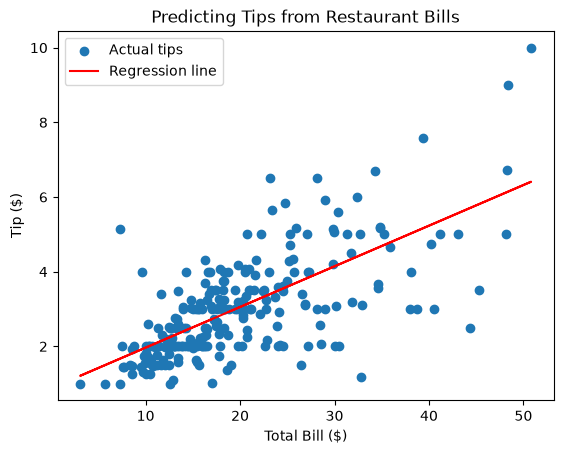

In [6]:
import matplotlib.pyplot as plt

y_pred = model.predict(X)

plt.scatter(X["total_bill"], y, label="Actual tips")
plt.plot(X["total_bill"], y_pred, color="red", label="Regression line")

plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.title("Predicting Tips from Restaurant Bills")
plt.legend()
plt.show()

In [7]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

print(iris.frame.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [8]:
X_iris = iris.data
y_iris = iris.target

print("Number of flowers:", len(X_iris))
print("Features:", list(X_iris.columns))
print("Species names:", list(iris.target_names))

Number of flowers: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [9]:
from sklearn.model_selection import train_test_split

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.3,
    random_state=42
)

print("Training flowers:", len(X_train_iris))
print("Testing flowers:", len(X_test_iris))

Training flowers: 105
Testing flowers: 45


In [10]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_iris, y_train_iris)

accuracy = knn.score(X_test_iris, y_test_iris)

print("Test accuracy:", accuracy)

Test accuracy: 1.0


In [11]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=3, random_state=42)

tree.fit(X_train_iris, y_train_iris)

tree_accuracy = tree.score(X_test_iris, y_test_iris)

print("Decision tree test accuracy:", tree_accuracy)

Decision tree test accuracy: 1.0


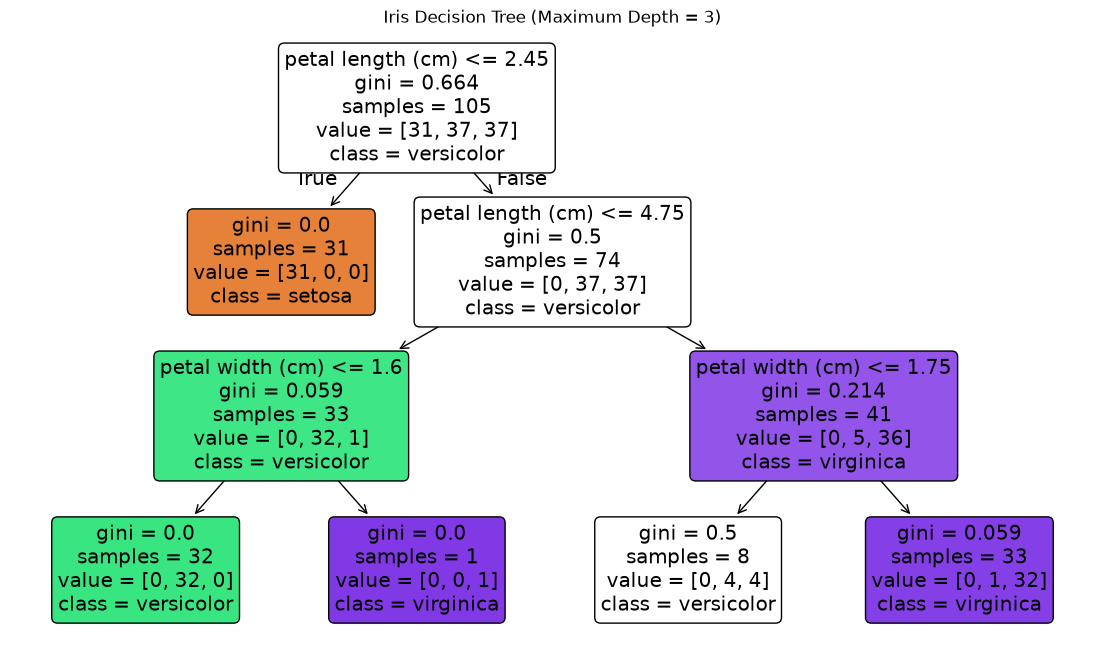

In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 8))

plot_tree(
    tree,
    feature_names=list(X_iris.columns),
    class_names=list(iris.target_names),
    filled=True,
    rounded=True
)

plt.title("Iris Decision Tree (Maximum Depth = 3)")
plt.show()

In [13]:
tree_unlimited = DecisionTreeClassifier(random_state=42)

tree_unlimited.fit(X_train_iris, y_train_iris)

print("Unlimited tree training accuracy:",
      tree_unlimited.score(X_train_iris, y_train_iris))

print("Unlimited tree test accuracy:",
      tree_unlimited.score(X_test_iris, y_test_iris))

Unlimited tree training accuracy: 1.0
Unlimited tree test accuracy: 1.0


In [14]:
print("Model                  Train accuracy   Test accuracy")

print("Shallow tree:         ",
      round(tree.score(X_train_iris, y_train_iris), 3),
      "             ",
      round(tree.score(X_test_iris, y_test_iris), 3))

print("Unlimited tree:       ",
      round(tree_unlimited.score(X_train_iris, y_train_iris), 3),
      "             ",
      round(tree_unlimited.score(X_test_iris, y_test_iris), 3))

Model                  Train accuracy   Test accuracy
Shallow tree:          0.952               1.0
Unlimited tree:        1.0               1.0


The shallow decision tree achived .952 traning accuracy and 1.0 test accuracy.while the unlimited tree achived 1.0 training accuracy and 1.0 test accuracy .the unlimited tree pass the traning data perfectly, whover, it didn't pass the the test accuray.   the compariosn dosent shown a loss of the test performance from overfiting, although the unlimted tree could still generalize less well to the other data.

In [15]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X_iris.columns
)

prediction = knn.predict(new_flower)

print("Predicted species:", iris.target_names[prediction[0]])

Predicted species: setosa


In this lab, I trained a linear regression model to predict restaurant tips from total bills plus a  two classifiers to predict iris flower species from flower measurements. Both the k-nearest neighbors (kNN) model and the shallow decision tree achieved 1.00 test accuracy, correctly classifying all 45 test flowers. I would choose the shallow decision tree because it achieved 1.0 test accuracy and is easier to explain than an unlimited-depth tree. it could make mistakes when predicting flowers with differnet measurements that differ significantly from the sample in the dataset. Although the test results were excellent, it is not guarantee that the model will always be correct on future prediction. If a similar model were used to make predictions about people, a bias risk would be that the training data might underrepresent certain groups, leading to less accurate predictions for them.